# Inference and evaluation

This notebook accepts DINOv2 architecture checkpoints from vision pretraining
(`train_vision_dinov2.py`) and staged fine-tuning (`train_tot_dinov2.py`).

Vision checkpoints support vision plots and metrics. They do not contain a trained
pose head, so pose evaluation is skipped. Joint checkpoints support both vision and
pose evaluation. Pose inference uses predicted occupancy bins and predicted
descriptor matches; GT camera poses are used only to score the predictions. The
optional vision subset is selected using GT cylinder matches and a valid camera
baseline.


In [20]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset

from dataset import SceneTwoPairsDataset
from model_dinov2 import PairImageCylinderModel, gt_bin_matches
from utils import plot_estimated_cylinders_on_images, plot_relative_pose, pose_to_text

# Use best_vision.pt from train_vision_dinov2.py or best_pose.pt from train_tot_dinov2.py.
CHECKPOINT = Path("arrhenius_dinov2/slurm_train_tot_dinov2_5703024/checkpoints/best_pose.pt")
TEST_DATASET = Path("testdataset")

VISION_ON_GT_POSE_SUBSET = False  # Limit vision metrics to pairs with GT pose matches.
MODEL_VERSION = "DINOv2 best_pose"  # Descriptive label for plots.
INFERENCE_BATCH_SIZE = 4
VISION_SAMPLE_IDX = 1
IMG_SIZE = 224
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
OCC_THRESHOLD = 0.3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT)
print("Test dataset:", TEST_DATASET)


Device: cuda
GPU: NVIDIA GeForce RTX 3070
Checkpoint: arrhenius_dinov2/slurm_train_tot_dinov2_5703024/checkpoints/best_pose.pt
Test dataset: testdataset


In [21]:
import torch.nn.functional as F

checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
training_args = checkpoint.get("args", {})
state = checkpoint["model_state_dict"]
training_stage = checkpoint.get("training_stage", "")
IS_VISION_CHECKPOINT = training_stage.startswith("vision_")
HAS_TRAINED_POSE = not IS_VISION_CHECKPOINT and "pose_head.token_mlp.0.weight" in state

model_kwargs = dict(
    img_size=training_args.get("img_size", 224),
    patch_size=tuple(training_args.get("patch_size", (16, 4))),
    in_chans=3,
    embed_dim=training_args.get("embed_dim", 192),
    depth=training_args.get("depth", 4),
    num_heads=training_args.get("num_heads", 4),
    num_bins=training_args.get("num_bins", 128),
    dropout=training_args.get("dropout", 0.1),
)

if HAS_TRAINED_POSE:
    scale = state["pose_head.input_scale"]
    model_kwargs.update(
        pose_embed_dim=state["pose_head.token_mlp.0.weight"].shape[0],
        pose_depth=len({key.split(".")[3] for key in state
                        if key.startswith("pose_head.blocks.layers.")}),
        fov_degrees=float(scale[0]) * 360 / np.pi,
        radius_scale=float(scale[1]),
        distance_scale=float(scale[2]),
    )

model = PairImageCylinderModel(**model_kwargs)
if IS_VISION_CHECKPOINT:
    # Vision pretraining saves a full model state, but its pose head is untrained.
    vision_state = {key: value for key, value in state.items()
                    if key.startswith(("backbone.", "vision_head.", "corr_decoder."))}
    expected = {key for key in model.state_dict()
                if key.startswith(("backbone.", "vision_head.", "corr_decoder."))}
    if set(vision_state) != expected:
        raise ValueError("Vision checkpoint does not match the model's vision modules.")
    model.load_state_dict(vision_state, strict=False)
else:
    model.load_state_dict(state, strict=True)
model = model.to(DEVICE).eval()
history = checkpoint.get("history")
GT_OCC_THRESHOLD = training_args.get("occ_thresh", 0.5)
print(f"Loaded checkpoint: {CHECKPOINT}")
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print("Training stage:", training_stage or "unspecified")
print("Trained pose head:", HAS_TRAINED_POSE)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
if HAS_TRAINED_POSE:
    print("Pose matching: predicted occupancy bins and descriptor matches (no GT cylinders).")
else:
    print("Vision-only checkpoint: pose evaluation will be skipped.")


Using cache found in /home2/johannae/.cache/torch/hub/facebookresearch_dinov2_main


Loaded checkpoint: arrhenius_dinov2/slurm_train_tot_dinov2_5703024/checkpoints/best_pose.pt
Checkpoint epoch: 190
Training stage: pose_refine
Trained pose head: True
Model parameters: 26,456,649
Pose matching: predicted occupancy bins and descriptor matches (no GT cylinders).


In [22]:
infer_dataset = SceneTwoPairsDataset(
    root_dir=str(TEST_DATASET),
    image_size=training_args.get("img_size", IMG_SIZE),
    return_two_pairs=False,
)
infer_loader = DataLoader(
    infer_dataset, batch_size=INFERENCE_BATCH_SIZE,
    shuffle=False, num_workers=0,
)

# Determine the same eligible subset using only GT labels, before inference.
pose_subset_indices = []
for sample_index, sample in enumerate(infer_dataset.samples):
    pair = sample.pair
    gt_a = torch.as_tensor(pair["vision1"], dtype=torch.float32)
    gt_b = torch.as_tensor(pair["vision2"], dtype=torch.float32)
    matches = gt_bin_matches(gt_a.unsqueeze(0), gt_b.unsqueeze(0), GT_OCC_THRESHOLD)[0]
    if len(matches) < 2:
        continue
    camera_a = pair.get("camera1", sample.scene_camera1)
    camera_b = pair.get("camera2", sample.scene_camera2)
    pose = infer_dataset._relative_pose_2d(camera_a, camera_b)
    if not torch.isfinite(pose).all():
        raise ValueError(f"Nonfinite GT pose in sample {sample_index}")
    if pose[:2].norm() > 1e-6:
        pose_subset_indices.append(sample_index)

vision_loader = (
    DataLoader(Subset(infer_dataset, pose_subset_indices),
               batch_size=INFERENCE_BATCH_SIZE, shuffle=False, num_workers=0)
    if VISION_ON_GT_POSE_SUBSET else infer_loader
)
print("Inference dataset size:", len(infer_dataset))
print("GT-eligible pose pairs:", len(pose_subset_indices))
print("Vision evaluated on:", "GT pose subset" if VISION_ON_GT_POSE_SUBSET else "all pairs")


Inference dataset size: 492
GT-eligible pose pairs: 492
Vision evaluated on: all pairs


In [23]:
batch = next(iter(infer_loader))
img_a, vision_a, img_b, vision_b, pose_ab = (x.to(DEVICE) for x in batch)
model.eval()
with torch.no_grad():
    if HAS_TRAINED_POSE:
        pred_vision, pred_vision_b, pred_pose, pose_info = model(
            img_a, img_b,
            target_vision_a=vision_a,
            target_vision_b=vision_b,
            matching_mode="predicted",
            return_pose_inputs=True,
            pred_occ_thresh=OCC_THRESHOLD,
        )
    else:
        pred_vision, pred_vision_b, _ = model(
            img_a, img_b, compute_pose=False, return_corr=False,
        )
        pred_pose, pose_info = None, None
if not 0 <= VISION_SAMPLE_IDX < len(img_a):
    raise IndexError("VISION_SAMPLE_IDX is outside this batch")
pose_sample_valid = False
if HAS_TRAINED_POSE:
    pose_sample_valid = (
        pose_info["pose_valid"][VISION_SAMPLE_IDX]
        & (pose_ab[VISION_SAMPLE_IDX, :2].norm() > 1e-6)
    ).item()
print("pred_vision shape:", pred_vision.shape)
if HAS_TRAINED_POSE:
    print("pred_pose shape:", pred_pose.shape)
    print("Pose eligible for selected sample:", pose_sample_valid)


pred_vision shape: torch.Size([4, 128, 4])
pred_pose shape: torch.Size([4, 4])
Pose eligible for selected sample: True


In [24]:
from metrics import evaluate_vision

class VisionOnlyModel(torch.nn.Module):
    """Let the existing vision evaluator call forward without GT matches."""
    def __init__(self, joint_model):
        super().__init__()
        self.joint_model = joint_model

    def forward(self, img_a, img_b, **kwargs):
        kwargs["compute_pose"] = False
        return self.joint_model(img_a, img_b, **kwargs)

vision_metrics = evaluate_vision(
    VisionOnlyModel(model),
    vision_loader,
    DEVICE,
    occ_threshold=OCC_THRESHOLD,
)



VISION PERFORMANCE

OCCUPANCY, occ_threshold=0.30
------------------------------------------------------------------------------
  Accuracy   Precision    Recall        F1   F1 ±1 bin
     0.927       0.500     0.544     0.521       0.692

GEOMETRY
------------------------------------------------------------------------------
                 MAE      RMSE      Bias      Corr  Pred std    GT std
Radius         0.075     0.101     0.000     0.754     0.126     0.154
Depth          0.881     1.372    -0.115     0.966     5.098     5.294

TOLERANCE ACCURACY
------------------------------------------------------------------------------
Radius         ±0.05 m     ±0.10 m     ±0.20 m
                 0.476       0.733       0.934

Depth           ±0.5 m      ±1.0 m      ±2.0 m
                 0.469       0.710       0.896


In [25]:
from metrics import evaluate_pose

if HAS_TRAINED_POSE:
    pose_metrics = evaluate_pose(
        model,
        infer_loader,
        DEVICE,
        pred_occ_threshold=OCC_THRESHOLD,
    )
else:
    pose_metrics = None
    print("Skipping pose evaluation: this checkpoint has no trained pose head.")


CAMERA POSE PERFORMANCE
Pose method:            Learned pose with predicted bins and matches

Seen pairs:             492
Test pairs:             492
Successful poses:       465
Prediction failures:    27
Success rate:           0.945
Excluded GT pairs:      0

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   18.37°
Median:                 10.87°
P90:                    33.66°

YAW ERROR
----------------------------------------
Mean:                   2.50°
Median:                 1.35°
P90:                    5.78°

ACCURACY THRESHOLDS — successful poses only
----------------------------------------
<  5°: T= 25.6% | Yaw= 88.4%
< 10°: T= 46.5% | Yaw= 95.7%
< 20°: T= 73.5% | Yaw= 99.1%
< 30°: T= 85.4% | Yaw=100.0%


## 1. Input image pair


In [26]:
# Plots are controlled by INFERENCE_SHOW_IMAGES in the following cells.


## 2. Vision prediction

Compare the predicted `(occupancy, radius, depth)` against the ground truth for image A.


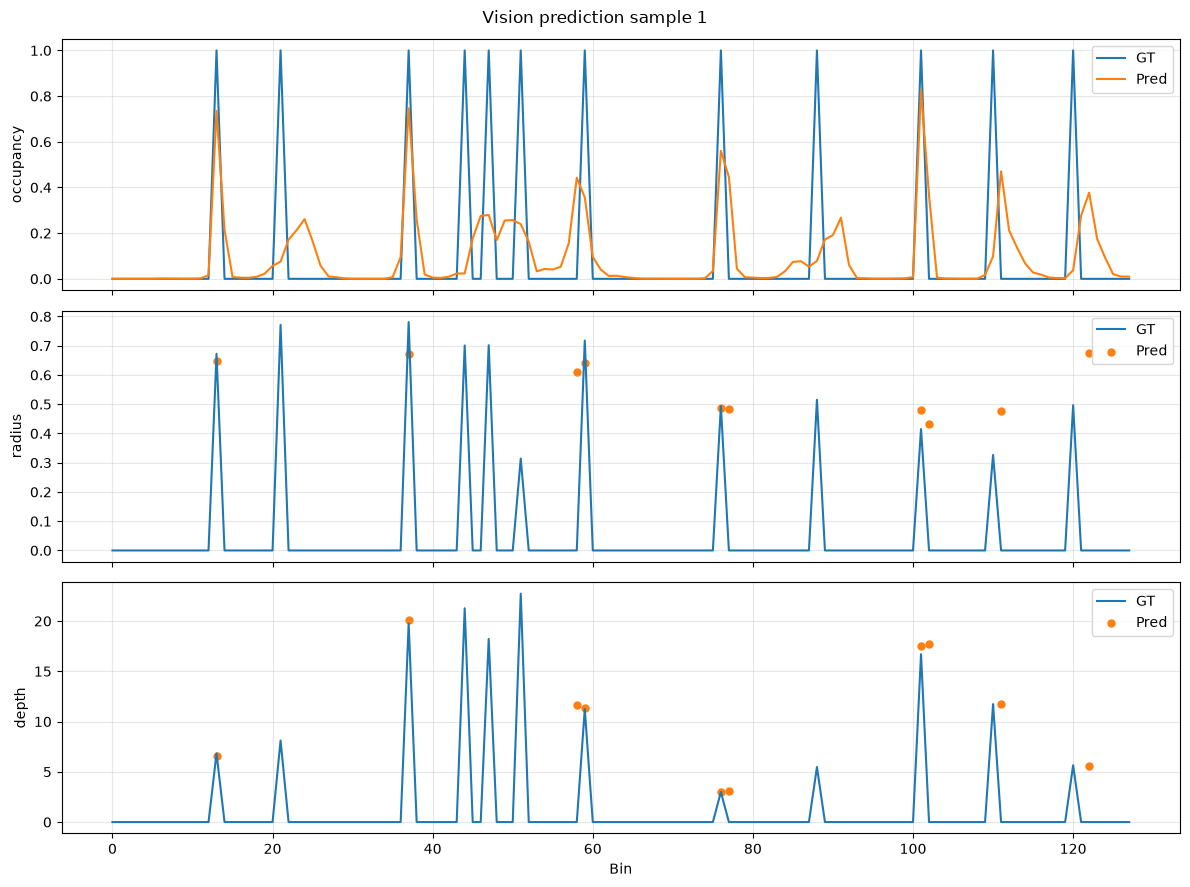

In [27]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(vision_a.shape[1])
PLOT_OCC_THRESHOLD = OCC_THRESHOLD
if INFERENCE_SHOW_IMAGES:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]
    pr_occ = pred_vision[sample_idx, :, 0].detach().cpu().numpy()
    for j, ax in enumerate(axes):
        gt = vision_a[sample_idx, :, j].detach().cpu().numpy()
        pr = pred_vision[sample_idx, :, j].detach().cpu().numpy()
        ax.plot(bins, gt, label="GT", color="tab:blue")
        if j == 0:
            ax.plot(bins, pr, label="Pred", color="tab:orange")
        else:
            pr_mask = pr_occ > PLOT_OCC_THRESHOLD
            ax.scatter(bins[pr_mask], pr[pr_mask], label="Pred", color="tab:orange", s=25)
        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"Vision prediction sample {sample_idx}")
    plt.tight_layout()
    plt.show()


## 3. Estimated cylinders and input images


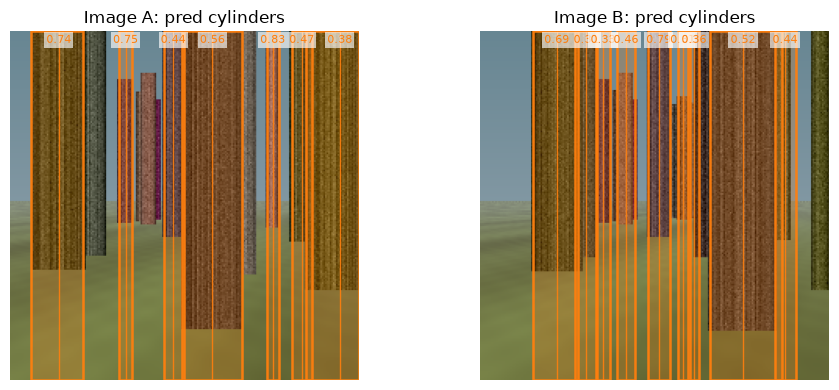

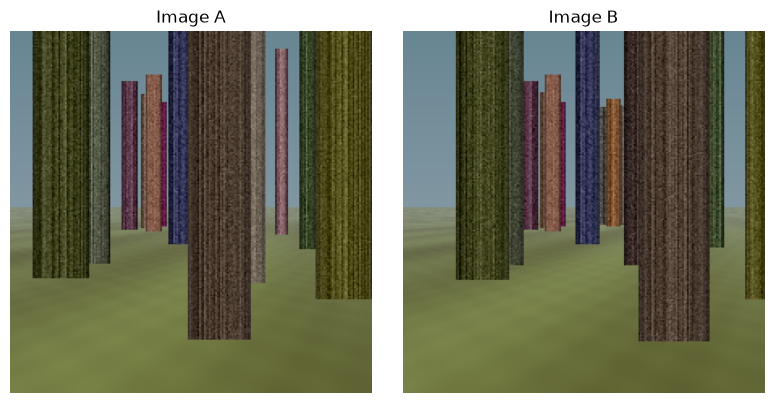

In [28]:
if INFERENCE_SHOW_IMAGES:
    fig_cyl, axes_cyl = plot_estimated_cylinders_on_images(
        [img_a[sample_idx], img_b[sample_idx]],
        [pred_vision[sample_idx], pred_vision_b[sample_idx]],
        titles=["Image A: pred cylinders", "Image B: pred cylinders"],
        occ_threshold=PLOT_OCC_THRESHOLD,
        flip_x=False,
    )
    plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[sample_idx].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[sample_idx].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


## 4. Relative pose


Predikterade matchningar: 4
Modellen kan uppskatta pose: True
GT-förflyttning: 1.0


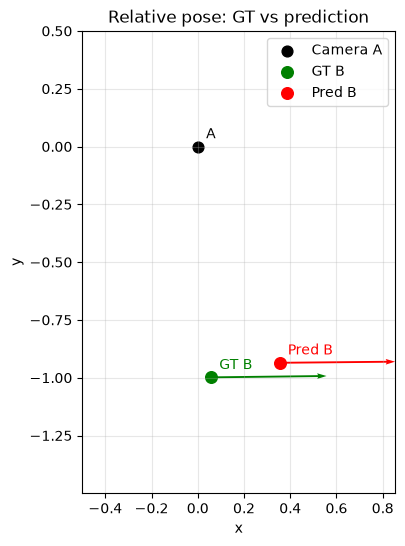

In [29]:
i = sample_idx
print("Predikterade matchningar:", pose_info["num_matches"][i].item())
print("Modellen kan uppskatta pose:", pose_info["pose_valid"][i].item())
print("GT-förflyttning:", pose_ab[i, :2].norm().item())

if not HAS_TRAINED_POSE:
    print("No trained pose head in this checkpoint; pose visualization is unavailable.")
elif pose_sample_valid:
    gt_pose = pose_ab[sample_idx].detach().cpu()
    pred_pose_sample = pred_pose[sample_idx].detach().cpu()
    if INFERENCE_SHOW_TEXT:
        print("GT :", pose_to_text(gt_pose))
        print("Pred:", pose_to_text(pred_pose_sample))
    if INFERENCE_SHOW_IMAGES:
        plot_relative_pose(gt_pose, pred_pose_sample)
else:
    print("Selected sample has no evaluable pose; select another VISION_SAMPLE_IDX.")


## 5. Training history (optional)

Plot epoch-aligned loss curves stored in the selected checkpoint.


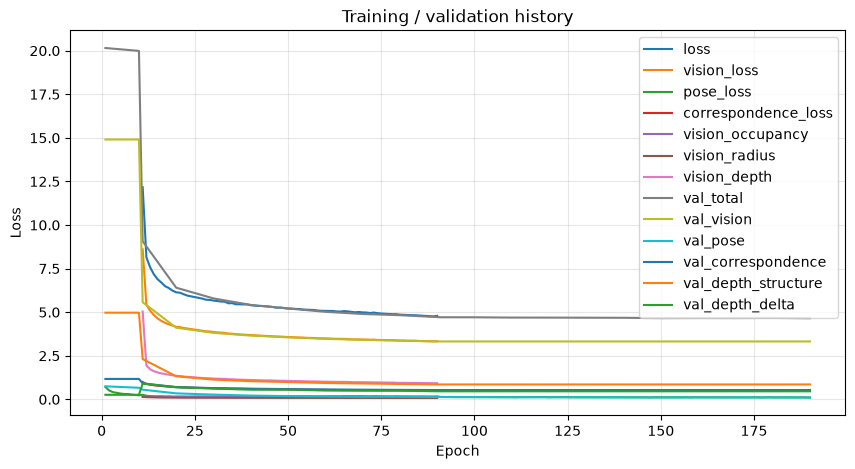

In [30]:
# Plot epoch-aligned loss curves when the selected checkpoint contains history.
if isinstance(history, dict):
    epochs = history.get("epoch", [])
    val_epochs = history.get("val_epoch", [])
    train_keys = ["loss", "vision_loss", "pose_loss", "correspondence_loss",
                  "vision_occupancy", "vision_radius", "vision_depth"]
    val_keys = ["val_total", "val_vision", "val_pose", "val_correspondence",
                "val_depth_structure", "val_depth_delta"]
    plt.figure(figsize=(10, 5))
    plotted = False
    for keys, xs in [(train_keys, epochs), (val_keys, val_epochs)]:
        for key in keys:
            ys = history.get(key, [])
            if len(xs) and len(ys) == len(xs):
                plt.plot(xs, ys, label=key)
                plotted = True
    if plotted:
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training / validation history")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    else:
        plt.close()
        print("History present, but no matching epoch-aligned loss curves.")
else:
    print("No training history stored in the selected checkpoint.")


In [31]:
from torchvision import transforms
from forest_dataset import ForestPairDataset
from metrics import evaluate_pose_forest

skrylle_dir = Path(".") / "forestdataset" / "skrylle"
strides = [1, 5, 10, 20]

skrylle_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

skrylle_metrics_by_stride = {}

for stride in strides:
    poses_file = f"relative_poses_stride_{stride}.json"

    dataset = ForestPairDataset(
        dataset_dir=skrylle_dir,
        poses_file=poses_file,
        transform=skrylle_transform,
    )
    loader = DataLoader(
        dataset,
        batch_size=8,
        shuffle=False,
        num_workers=4,
        pin_memory=DEVICE.type == "cuda",
    )

    print(f"\nEvaluating Skrylle, stride {stride} ({len(dataset)} pairs)")
    skrylle_metrics_by_stride[stride] = evaluate_pose_forest(
        model,
        loader,
        DEVICE,
        predict_pose=lambda m, a, b: m.predict_pose_from_images(a, b),
    )


Evaluating Skrylle, stride 1 (974 pairs)
FOREST CAMERA POSE PERFORMANCE
Pose method:            Custom forest pose prediction

Test pairs:             974
Successful poses:       974
Prediction failures:    0
Success rate:           1.000
Excluded GT pairs:      0

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   101.41°
Median:                 105.90°
P90:                    159.29°

YAW ERROR
----------------------------------------
Mean:                   1.97°
Median:                 1.68°
P90:                    4.02°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T=  1.6% | Yaw= 95.2%
< 10°: T=  3.4% | Yaw= 99.9%
< 20°: T=  6.9% | Yaw=100.0%
< 30°: T=  9.2% | Yaw=100.0%

Evaluating Skrylle, stride 5 (970 pairs)
FOREST CAMERA POSE PERFORMANCE
Pose method:            Custom forest pose prediction

Test pairs:             970
Successful poses:       970
Prediction failures:    0
Success rate:           1.000
Excluded